# Junk Food Multi-class Classification with KNN (Colab / Local)

Classifies every frame into exactly one **ad type** (`tip`) of `tip-multiclass-dataset.zip` with a **k-nearest-neighbors**
classifier over frozen embeddings. It uses the same six pretrained extractors as `KNN-binary-classification.ipynb`.

## Flow

Run the notebook top to bottom.

1. **Setup / data / split** - identical to the other multi-class notebooks, so the train/val/test images are the same.
2. **Feature extraction** - each frozen extractor (ResNeXt-101, EfficientNet V2-M, ConvNeXt Base, ViT-B/16, Swin V2-B,
   DINOv2 ViT-B/14) embeds train/val/test once; embeddings are L2-normalized.
3. **KNN** - the score of a class is the (optionally similarity-weighted) fraction of the *k* nearest training images
   (cosine similarity, exact search) that belong to it; the prediction is the class with the highest score.
4. **Model selection on validation** - per extractor, `k` and the weighting are chosen by validation macro-F1. The
   extractor with the best validation macro-F1 is the primary result.
5. **Test evaluation** - the frozen configurations are scored once on the test split.

There are no epochs or early stopping: the extractors are frozen and "fitting" a KNN just stores the training embeddings.

## Environment Setup (Colab or Local)

Run the setup cell below **first**. It auto-detects Google Colab and, when running there, installs missing
dependencies, mounts Google Drive and extracts the dataset zip onto the local Colab disk (much faster than reading
thousands of JPEGs over Drive). Pretrained weights are downloaded fresh each session.

**Colab checklist**
1. `Runtime > Change runtime type > GPU` (T4 is enough; A100/L4 are faster).
2. Upload `tip-multiclass-dataset.zip` (from `unhealthy-dataset-generator`; it contains `tip_multiclass_dataset.csv` and `images/`) to Drive.
3. Add a Colab Secret (key icon in the left sidebar) named `MULTICLASS_DATASET_ZIP_PATH` with the path of that `.zip`, either absolute (`/content/drive/MyDrive/datasets/tip-multiclass-dataset.zip`) or relative to `/content/drive` (`MyDrive/datasets/tip-multiclass-dataset.zip`), enable notebook access, then run all cells.

Locally the dataset is read from `./dataset` (the extracted zip; override with the `JUNK_FOOD_DATASET_DIR` environment variable).

In [1]:
# =====================================================================
# ENVIRONMENT SETUP - runs on Google Colab and locally.
#
# Colab:  installs missing packages, mounts Google Drive and extracts the
#         dataset zip to the local disk.
# Local:  no-op besides resolving ./dataset .
# =====================================================================
import os
import shutil
import subprocess
import sys
import zipfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules or bool(os.environ.get("COLAB_RELEASE_TAG"))

CSV_NAME = "tip_multiclass_dataset.csv"
IMAGES_DIR_NAME = "images"
LOCAL_EXTRACT_DIR = Path("/content/multiclass_dataset")

# Local dataset location (used when not on Colab). Override with JUNK_FOOD_DATASET_DIR.
LOCAL_DATASET_DIR = next((p / "dataset" for p in (Path.cwd(), Path.cwd().parent) if (p / "dataset").exists()),
                         Path.cwd() / "dataset")


def _get_dataset_zip_path():
    """Colab Secret MULTICLASS_DATASET_ZIP_PATH, falling back to the environment variable of the same name."""
    if IN_COLAB:
        try:
            from google.colab import userdata

            value = userdata.get("MULTICLASS_DATASET_ZIP_PATH")
            if value:
                return value.strip()
        except Exception:  # secret missing or notebook access not granted
            pass
    return os.environ.get("MULTICLASS_DATASET_ZIP_PATH", "").strip() or None


def _find_dataset_root(base):
    """Return the folder holding tip_multiclass_dataset.csv and images/ (zips may add a wrapping folder)."""
    for current_dir, subdirs, file_names in os.walk(base):
        if CSV_NAME in file_names and IMAGES_DIR_NAME in subdirs:
            return Path(current_dir)
    return Path(base)


def _pip_install(*packages):
    missing = []
    for pkg, module in packages:
        try:
            __import__(module)
        except ImportError:
            missing.append(pkg)
    if missing:
        print(f"Installing: {', '.join(missing)}")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)


if IN_COLAB:
    print("Google Colab detected.")

    DATASET_ZIP_PATH = _get_dataset_zip_path()
    if not DATASET_ZIP_PATH:
        raise ValueError(
            "MULTICLASS_DATASET_ZIP_PATH is not set. Add a Colab Secret named MULTICLASS_DATASET_ZIP_PATH "
            "(key icon in the left sidebar, enable notebook access) pointing to tip-multiclass-dataset.zip "
            "in Google Drive, e.g. MyDrive/datasets/tip-multiclass-dataset.zip."
        )

    from google.colab import drive

    drive.mount("/content/drive")
    drive_source = (Path(DATASET_ZIP_PATH) if DATASET_ZIP_PATH.startswith("/content/")
                    else Path("/content/drive") / DATASET_ZIP_PATH.lstrip("/"))
    if not drive_source.exists():
        raise FileNotFoundError(f"Nothing found at {drive_source}. Check MULTICLASS_DATASET_ZIP_PATH.")

    # Always start from a clean folder so a previous/partial extraction can't leave stale files behind.
    if LOCAL_EXTRACT_DIR.exists():
        shutil.rmtree(LOCAL_EXTRACT_DIR)
    if drive_source.suffix.lower() == ".zip":
        print(f"Extracting {drive_source.name} ({drive_source.stat().st_size / 1e9:.2f} GB) to {LOCAL_EXTRACT_DIR}...")
        # Copy the archive off Drive first: one sequential read is far faster than unzipping over the mount.
        staged_zip = Path("/content") / drive_source.name
        shutil.copyfile(drive_source, staged_zip)
        with zipfile.ZipFile(staged_zip) as zf:
            zf.extractall(LOCAL_EXTRACT_DIR)
        staged_zip.unlink()
    else:
        print(f"Copying dataset folder from Drive to {LOCAL_EXTRACT_DIR} (slow; a .zip is much faster)...")
        shutil.copytree(drive_source, LOCAL_EXTRACT_DIR)
    DATASET_DIR = _find_dataset_root(LOCAL_EXTRACT_DIR)

    # Colab VMs have spare CPU cores for image decoding.
    DATALOADER_WORKERS = 2
else:
    print("Local environment detected.")
    DATASET_DIR = _find_dataset_root(LOCAL_DATASET_DIR) if LOCAL_DATASET_DIR.exists() else LOCAL_DATASET_DIR
    DATALOADER_WORKERS = 0

DATASET_DIR = Path(os.environ.get("JUNK_FOOD_DATASET_DIR", DATASET_DIR)).expanduser()

# --- Validate the dataset layout before anything expensive runs ---------
_csv = DATASET_DIR / CSV_NAME
_images = DATASET_DIR / IMAGES_DIR_NAME
_problems = [str(p) for p in (_csv, _images) if not p.exists()]
if _problems:
    raise FileNotFoundError(
        f"Dataset not found at {DATASET_DIR}. Missing: {', '.join(_problems)}.\n"
        "Expected layout:\n"
        f"  <dataset dir>/{CSV_NAME}\n"
        f"  <dataset dir>/{IMAGES_DIR_NAME}/*.jpg"
    )

print(f"Dataset dir: {DATASET_DIR}")
print(f"  images: {sum(1 for _ in _images.glob('*.jpg'))}")
print(f"  dataloader workers: {DATALOADER_WORKERS}")

Google Colab detected.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Extracting tip-multiclass-dataset.zip (0.36 GB) to /content/multiclass_dataset...
Dataset dir: /content/multiclass_dataset
  images: 3446
  dataloader workers: 2


In [2]:
import json
import platform
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
)
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# DATASET_DIR comes from the setup cell (extracted zip on Colab, ./dataset locally).
DATASET_ROOT = Path(DATASET_DIR)
CSV_PATH = DATASET_ROOT / CSV_NAME
IMAGES_DIR = DATASET_ROOT / IMAGES_DIR_NAME
IMG_EXTS = (".jpg", ".jpeg", ".png")

In [3]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    props = torch.cuda.get_device_properties(0)
    vram_gb = props.total_memory / 1e9
    print(f"GPU: {props.name} ({vram_gb:.1f} GB)")
    EMBEDDING_BATCH_SIZE = 16 if vram_gb < 6 else (24 if vram_gb < 10 else 32)
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
    print("Using Apple Metal Performance Shaders (MPS)")
    EMBEDDING_BATCH_SIZE = 8
else:
    DEVICE = torch.device("cpu")
    EMBEDDING_BATCH_SIZE = 8
    print("GPU not available, using CPU")
    if globals().get("IN_COLAB", False):
        print("On Colab, enable a GPU via Runtime > Change runtime type > T4 GPU "
              "and re-run from the setup cell; CPU is impractically slow.")

GPU: Tesla T4 (15.6 GB)


## Data and group-aware split

`tip_multiclass_dataset.csv` has one row per image: `image_name`, `tip` (class id), `tip_label` (class description) and
`group`. Each frame has exactly **one** class (multi-class, not multi-label). A group is an ad creative (`ad_XXXX`) or a
non-ad source video (`non_ad_<video>`); its frames are near-duplicates, so **whole groups** are assigned to
train/val/test (target 70/15/15 of the frames of each class, seed 42) and no group appears in two splits. A few
creatives contain frames of two classes (e.g. a supermarket ad that shows food only in some frames); the split works on
per-group class counts, so those groups are handled too.

Classes with fewer than 3 groups cannot appear in all splits: 1 group -> train only, 2 groups -> train + test (so the
class is still evaluated). The split summary prints a `NOTE` for these classes; their val/test metrics are very noisy.

Set `PILOT = True` for a fast run on a group-aware ~20% subset.

In [4]:
# =====================================================================
# PILOT MODE: fast end-to-end pipeline check on a group-aware subset.
# =====================================================================
PILOT = False
PILOT_FRACTION = 0.20

# Short English names for the tip ids (descriptions come from the CSV).
SHORT_CLASS_NAMES = {
    0: "non_ad",
    2: "food_brand",
    3: "food_by_nonfood_co",
    5: "supermarket_food",
    6: "supermarket_nonfood",
    7: "restaurant_food",
    8: "restaurant_nonfood",
}

print("Loading CSV...")
raw_df = pd.read_csv(CSV_PATH, dtype=str, encoding="utf-8-sig")
missing_cols = {"image_name", "tip", "tip_label", "group"} - set(raw_df.columns)
if missing_cols:
    raise ValueError(f"{CSV_NAME} is missing columns: {sorted(missing_cols)}")
raw_df = raw_df.apply(lambda col: col.str.strip())

if raw_df["image_name"].duplicated().any():
    raise ValueError(f"Duplicated image_name rows: {raw_df.loc[raw_df['image_name'].duplicated(), 'image_name'].tolist()[:10]}")
raw_df["tip"] = pd.to_numeric(raw_df["tip"], errors="coerce")
if raw_df["tip"].isna().any():
    raise ValueError(f"Non-numeric tip values in {int(raw_df['tip'].isna().sum())} rows")
raw_df["tip"] = raw_df["tip"].astype(int)
empty_group = raw_df["group"].isna() | (raw_df["group"] == "")
if empty_group.any():
    raise ValueError(f"{int(empty_group.sum())} rows have no group, e.g. {raw_df.loc[empty_group, 'image_name'].tolist()[:10]}")

image_lookup = {p.name: p for p in IMAGES_DIR.iterdir() if p.suffix.lower() in IMG_EXTS}
missing_images = sorted(set(raw_df["image_name"]) - set(image_lookup))
if missing_images:
    raise FileNotFoundError(f"{len(missing_images)} CSV images are missing from images/, e.g. {missing_images[:10]}")
extra_images = sorted(set(image_lookup) - set(raw_df["image_name"]))
if extra_images:
    print(f"WARNING: {len(extra_images)} images in images/ are not in the CSV and are ignored, e.g. {extra_images[:5]}")

CLASS_IDS = sorted(raw_df["tip"].unique().tolist())
CLASS_DESCRIPTIONS = raw_df.groupby("tip")["tip_label"].first().to_dict()
CLASS_NAMES = [SHORT_CLASS_NAMES.get(t, f"tip_{t}") for t in CLASS_IDS]
NUM_CLASSES = len(CLASS_IDS)
TIP_TO_INDEX = {t: i for i, t in enumerate(CLASS_IDS)}

all_df = pd.DataFrame({
    "image_name": raw_df["image_name"],
    "image_path": raw_df["image_name"].map(lambda n: str(image_lookup[n])),
    "tip": raw_df["tip"],
    "tip_label": raw_df["tip_label"],
    "group": raw_df["group"],
})
all_df["y"] = all_df["tip"].map(TIP_TO_INDEX)
all_df["class_name"] = all_df["y"].map(lambda i: CLASS_NAMES[i])

print(f"\n{len(all_df)} images, {all_df['group'].nunique()} groups, {NUM_CLASSES} classes:")
print(pd.DataFrame({
    "tip": CLASS_IDS,
    "name": CLASS_NAMES,
    "images": [int((all_df["tip"] == t).sum()) for t in CLASS_IDS],
    "groups": [all_df.loc[all_df["tip"] == t, "group"].nunique() for t in CLASS_IDS],
    "description": [CLASS_DESCRIPTIONS[t] for t in CLASS_IDS],
}).to_string(index=False))
mixed = all_df.groupby("group")["tip"].nunique()
if (mixed > 1).any():
    print(f"\nGroups with frames of more than one class: {sorted(mixed[mixed > 1].index)}")


SEED = 42
SPLIT_FRACTIONS = {"train": 0.70, "val": 0.15, "test": 0.15}
# When a class has fewer groups than splits, its groups go to the splits in this order:
# 1 group -> train; 2 groups -> train + test (so the class is still evaluated); >= 3 -> all splits.
SUPPORT_ORDER = ("train", "test", "val")


def stratified_group_split(frame, label_col, group_col="group", fractions=SPLIT_FRACTIONS,
                           support_order=SUPPORT_ORDER, seed=SEED):
    """Assign whole groups to splits while keeping the per-class frame shares close to `fractions`.

    Groups (same creative / same source video) are atomic, so near-identical frames never
    cross splits. A group may contain frames of several classes; it is described by its
    per-class frame counts. Classes are processed from the one with the fewest groups to
    the one with the most; each carrier group (largest first, seeded order on ties) goes to
    the split with the largest remaining deficit for that class, then for total frames.
    A repair pass then guarantees every class has at least one group in the splits given by
    `support_order` (moving the smallest donor group that its own split can spare).

    Returns a dict group -> split name.
    """
    splits = list(fractions)
    counts = pd.crosstab(frame[group_col], frame[label_col])
    order = counts.index.to_numpy().copy()
    np.random.default_rng(seed).shuffle(order)
    counts = counts.loc[order]
    classes = list(counts.columns)
    sizes = counts.sum(axis=1)

    class_target = {s: counts.sum(axis=0) * f for s, f in fractions.items()}
    frame_target = {s: sizes.sum() * f for s, f in fractions.items()}
    filled = {s: pd.Series(0.0, index=classes) for s in splits}
    assignment = {}

    n_carriers = (counts > 0).sum(axis=0).sort_values(kind="stable")
    for cls in n_carriers.index:
        carriers = [g for g in counts.index if g not in assignment and counts.loc[g, cls] > 0]
        carriers.sort(key=lambda g: -counts.loc[g, cls])
        for g in carriers:
            split = max(splits, key=lambda s: (class_target[s][cls] - filled[s][cls],
                                               frame_target[s] - filled[s].sum()))
            assignment[g] = split
            filled[split] += counts.loc[g]

    def required(cls):
        return [s for s in support_order if s in splits][:min(int(n_carriers[cls]), len(splits))]

    def carriers_in(cls, split):
        return sum(1 for g, s in assignment.items() if s == split and counts.loc[g, cls] > 0)

    def can_leave(g, split):
        return all(carriers_in(c, split) > 1 or split not in required(c)
                   for c in classes if counts.loc[g, c] > 0)

    changed = True
    while changed:
        changed = False
        for cls in n_carriers.index:
            for split in required(cls):
                if carriers_in(cls, split):
                    continue
                donors = [g for g, s in assignment.items()
                          if s != split and counts.loc[g, cls] > 0 and can_leave(g, s)]
                if donors:
                    assignment[min(donors, key=lambda g: sizes[g])] = split
                    changed = True

    for cls in n_carriers.index:
        missing = [s for s in required(cls) if not carriers_in(cls, s)]
        if missing:
            print(f"  NOTE: class {cls!r} has no group in {missing} (its groups cannot be moved)")
        if n_carriers[cls] < len(splits):
            present = [s for s in splits if carriers_in(cls, s)]
            print(f"  NOTE: class {cls!r} has only {int(n_carriers[cls])} group(s); present in {present}")
    return assignment


def assert_no_group_leakage(frame, group_col="group", split_col="split"):
    splits_per_group = frame.groupby(group_col)[split_col].nunique()
    leaked = splits_per_group[splits_per_group > 1]
    assert leaked.empty, f"LEAKAGE: groups in more than one split: {list(leaked.index)}"


def print_split_summary(frame, label_col, group_col="group", split_col="split"):
    split_names = [s for s in SPLIT_FRACTIONS if s in set(frame[split_col])]
    frames = pd.crosstab(frame[label_col], frame[split_col]).reindex(columns=split_names, fill_value=0)
    groups = (frame.groupby([label_col, split_col])[group_col].nunique().unstack(fill_value=0)
              .reindex(index=frames.index, columns=split_names, fill_value=0))
    table = frames.astype(str) + " (" + groups.astype(str) + " gr)"
    total_groups = frame.groupby(label_col)[group_col].nunique().reindex(frames.index)
    table["total"] = frames.sum(axis=1).astype(str) + " (" + total_groups.astype(str) + " gr)"
    print("Frames (groups) per class and split:")
    print(table.to_string())
    totals = frames.sum(axis=0)
    print("\nFrames per split: " + ", ".join(
        f"{s}={int(totals[s])} ({totals[s] / totals.sum():.1%}, "
        f"{frame.loc[frame[split_col] == s, group_col].nunique()} groups)"
        for s in split_names))


if PILOT:
    print(f"\nPILOT MODE: keeping ~{PILOT_FRACTION:.0%} of the groups (class-balanced)")
    keep = stratified_group_split(all_df, label_col="tip",
                                  fractions={"keep": PILOT_FRACTION, "drop": 1.0 - PILOT_FRACTION},
                                  support_order=("keep",))
    all_df = all_df[all_df["group"].map(keep) == "keep"].reset_index(drop=True)
    print(f"  -> {len(all_df)} images")

print("\nSplitting...")
group_to_split = stratified_group_split(all_df, label_col="tip")
all_df["split"] = all_df["group"].map(group_to_split)
assert all_df["split"].notna().all()
assert_no_group_leakage(all_df)
print_split_summary(all_df.assign(cls=all_df["tip"].astype(str) + " " + all_df["class_name"]), label_col="cls")

train_df = all_df[all_df["split"] == "train"].reset_index(drop=True)
val_df = all_df[all_df["split"] == "val"].reset_index(drop=True)
test_df = all_df[all_df["split"] == "test"].reset_index(drop=True)
SPLIT_FRAMES = {"train": train_df, "val": val_df, "test": test_df}
Y = {split: frame["y"].to_numpy(dtype=np.int64) for split, frame in SPLIT_FRAMES.items()}
for split, frame in SPLIT_FRAMES.items():
    absent = [CLASS_NAMES[i] for i in range(NUM_CLASSES) if i not in set(Y[split])]
    if absent:
        print(f"  {split}: no images of {absent}")


def save_split_manifest(results_dir):
    """Split manifest (identical across the multi-class notebooks for the same dataset and seed)."""
    all_df[["image_name", "tip", "class_name", "group", "split"]].to_csv(Path(results_dir) / "split_manifest.csv", index=False)

Loading CSV...

3446 images, 112 groups, 7 classes:
 tip                name  images  groups                                                                                                                         description
   0              non_ad     810      26                                                                                                              No es anuncio (non_ad)
   2          food_brand    1620      45                                                                       Productos de alimentos o bebidas: compañía de alimentos/marca
   3  food_by_nonfood_co     100       2                                      Productos de alimentos o bebidas promocionados por compañias que no son de alimentos o bebidas
   5    supermarket_food     380      21                                            Supermercados o tiendas de conveniencia que promocionan productos de alimentos o bebidas
   6 supermarket_nonfood      93       8                                         Su

## Metrics

Single-label metrics on the argmax prediction: accuracy, balanced accuracy (mean per-class recall), macro
precision/recall/F1 (averaged over the classes present in the evaluated split, so a class absent from val does not
count as F1 = 0) and support-weighted F1. **Model selection always uses validation macro-F1**, because the classes are
very imbalanced (`food_brand` alone is ~47% of the frames). The test report also shows per-class
precision/recall/F1 and the confusion matrix (rows = true class, columns = predicted class).

In [5]:
def compute_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    present = np.unique(y_true)
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": float(np.mean(recall_score(y_true, y_pred, labels=present, average=None, zero_division=0))),
        "macro_precision": precision_score(y_true, y_pred, labels=present, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, labels=present, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, labels=present, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, labels=present, average="weighted", zero_division=0),
    }
    return {key: float(value) for key, value in metrics.items()}


METRIC_KEYS = ["accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1"]


def print_metrics(metrics, title, n_images=None, extra_lines=()):
    print("\n" + "=" * 60)
    print(title)
    print("=" * 60)
    for line in extra_lines:
        print(f"  {line}")
    if n_images is not None:
        print(f"  Images:            {n_images}")
    print(f"  Accuracy:          {metrics['accuracy']:.4f}")
    print(f"  Balanced accuracy: {metrics['balanced_accuracy']:.4f}")
    print(f"  Macro precision:   {metrics['macro_precision']:.4f}")
    print(f"  Macro recall:      {metrics['macro_recall']:.4f}")
    print(f"  Macro F1:          {metrics['macro_f1']:.4f}")
    print(f"  Weighted F1:       {metrics['weighted_f1']:.4f}")


def per_class_frame(y_true, y_pred):
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(NUM_CLASSES)), zero_division=0
    )
    return pd.DataFrame({
        "tip": CLASS_IDS, "class_name": CLASS_NAMES, "support": support,
        "precision": precision, "recall": recall, "f1": f1,
    })


def plot_confusion_matrix(y_true, y_pred, title, cmap="Blues"):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(title, fontsize=10)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    return cm


def report_configuration(title, y_true, y_pred, metrics, extra_lines=(), cmap="Blues"):
    """Full test report for one configuration: metrics, per-class report and confusion matrix."""
    print_metrics(metrics, title, n_images=len(y_true), extra_lines=extra_lines)
    print("\nPER-CLASS REPORT")
    print(classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)), target_names=CLASS_NAMES,
                                digits=4, zero_division=0))
    plot_confusion_matrix(y_true, y_pred, title, cmap=cmap)
    return per_class_frame(y_true, y_pred)


def show_image(path, title):
    fig, ax = plt.subplots(figsize=(8, 5))
    with Image.open(path) as image:
        ax.imshow(image.convert("RGB"))
    ax.axis("off")
    ax.set_title(title, fontsize=9)
    plt.tight_layout()
    plt.show()


def sample_test_indices(per_class=1):
    """Seeded random test images, `per_class` of every class present in test."""
    return [idx for _, frame in test_df.groupby("y")
            for idx in frame.sample(min(per_class, len(frame)), random_state=SEED).index]


def download_results(results_dir, archive_name):
    archive_path = shutil.make_archive(str(Path.cwd() / archive_name), "zip", results_dir)
    print(f"Archive: {archive_path}")
    if IN_COLAB:
        from google.colab import files

        files.download(archive_path)


def environment_metadata():
    return {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "scikit_learn": sklearn.__version__,
        "device": str(DEVICE),
        "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
        "seed": SEED,
        "pilot": PILOT,
        "classes": [{"tip": t, "name": n, "description": CLASS_DESCRIPTIONS[t]} for t, n in zip(CLASS_IDS, CLASS_NAMES)],
        "split_strategy": "group-aware stratified (whole groups per split), target 70/15/15 per class",
        "split_sizes": {split: len(frame) for split, frame in SPLIT_FRAMES.items()},
        "selection_metric": "validation macro-F1",
    }

## Feature extraction with pretrained models

KNN cannot extract visual features itself, so frozen pretrained models (classification heads removed) turn every image
into an embedding. Each model is loaded, run over train/val/test, then released, so only one model is in GPU memory
at a time. Set `EXTRACTOR_NAMES` to a subset to run fewer extractors. Times exclude model loading and weight downloads.

In [6]:
class ImagePathDataset(Dataset):
    """Loads images from disk for batched, frozen feature extraction."""

    def __init__(self, image_paths, transform):
        self.image_paths = list(image_paths)
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        with Image.open(self.image_paths[index]) as image:
            return self.transform(image.convert("RGB"))


def sync_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def image_loader(image_paths, transform, batch_size):
    return DataLoader(
        ImagePathDataset(image_paths, transform),
        batch_size=batch_size,
        shuffle=False,
        num_workers=DATALOADER_WORKERS,
        pin_memory=DEVICE.type == "cuda",
    )


import gc
import json
import shutil
import time

import torchvision.models as models
from torchvision import transforms as T
from torchvision.transforms import InterpolationMode

FEATURE_BATCH_SIZE = 64 if DEVICE.type == "cuda" else 16

EXTRACTOR_CONFIGS = [
    {
        "name": "ResNeXt-101",
        "loader": lambda: models.resnext101_32x8d(weights=models.ResNeXt101_32X8D_Weights.DEFAULT),
        "modifier": lambda m: nn.Sequential(*list(m.children())[:-1]),
        "transform": models.ResNeXt101_32X8D_Weights.DEFAULT.transforms(),
        "feature_dim": 2048,
    },
    {
        "name": "EfficientNet V2-M",
        "loader": lambda: models.efficientnet_v2_m(weights=models.EfficientNet_V2_M_Weights.DEFAULT),
        "modifier": lambda m: nn.Sequential(*list(m.children())[:-1]),
        "transform": models.EfficientNet_V2_M_Weights.DEFAULT.transforms(),
        "feature_dim": 1280,
    },
    {
        "name": "ConvNeXt Base",
        "loader": lambda: models.convnext_base(weights=models.ConvNeXt_Base_Weights.DEFAULT),
        # Keep the pretrained final LayerNorm + flatten; remove only the linear head.
        "modifier": lambda m: (m.classifier.__setitem__(2, nn.Identity()), m)[1],
        "transform": models.ConvNeXt_Base_Weights.DEFAULT.transforms(),
        "feature_dim": 1024,
    },
    {
        "name": "ViT-B/16",
        "loader": lambda: models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT),
        "modifier": lambda m: (setattr(m.heads, "head", nn.Identity()), m)[1],
        "transform": models.ViT_B_16_Weights.DEFAULT.transforms(),
        "feature_dim": 768,
    },
    {
        "name": "Swin V2-B",
        "loader": lambda: models.swin_v2_b(weights=models.Swin_V2_B_Weights.DEFAULT),
        "modifier": lambda m: nn.Sequential(*list(m.children())[:-1]),
        "transform": models.Swin_V2_B_Weights.DEFAULT.transforms(),
        "feature_dim": 1024,
    },
    {
        "name": "DINOv2",
        # Same pinned torch.hub commit as the CNN notebook (ViT-B/14 like the binary KNN notebook).
        "loader": lambda: torch.hub.load("facebookresearch/dinov2:c3c2683a13", "dinov2_vitb14", skip_validation=True),
        "modifier": lambda m: m,
        "transform": T.Compose([
            T.Resize(256, interpolation=InterpolationMode.BICUBIC),
            T.CenterCrop(224),
            T.ToTensor(),
            T.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ]),
        "feature_dim": 768,
    },
]
EXTRACTOR_NAMES = [config["name"] for config in EXTRACTOR_CONFIGS]


@torch.inference_mode()
def extract_features(model, transform, image_paths, feature_dim, description):
    chunks = []
    for batch in tqdm(image_loader(image_paths, transform, FEATURE_BATCH_SIZE), desc=description, leave=False):
        output = model(batch.to(DEVICE, non_blocking=True)).flatten(1).float()
        chunks.append(F.normalize(output, p=2, dim=1).cpu())
    features = torch.cat(chunks).numpy()
    if features.shape != (len(image_paths), feature_dim) or not np.isfinite(features).all():
        raise ValueError(f"Invalid features for {description}: shape={features.shape}")
    return features


features = {}          # extractor -> split -> (n_images, feature_dim) L2-normalized embeddings
feature_seconds = {}   # extractor -> split -> wall-clock seconds
for config in EXTRACTOR_CONFIGS:
    name = config["name"]
    if name not in EXTRACTOR_NAMES:
        continue
    model = config["modifier"](config["loader"]()).to(DEVICE).eval().requires_grad_(False)
    features[name], feature_seconds[name] = {}, {}
    for split, frame in SPLIT_FRAMES.items():
        sync_device()
        started = time.perf_counter()
        features[name][split] = extract_features(
            model, config["transform"], frame["image_path"].tolist(), config["feature_dim"], f"{name} - {split}"
        )
        sync_device()
        feature_seconds[name][split] = time.perf_counter() - started
    print(f"{name:<18} dim={config['feature_dim']:<5} "
          + "  ".join(f"{split}={secs:.1f}s" for split, secs in feature_seconds[name].items()))
    del model
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

ResNeXt-101 - train:   0%|          | 0/38 [00:00<?, ?it/s]

ResNeXt-101 - val:   0%|          | 0/8 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a337e318ea0>
Traceback (most recent call last):
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    <function _MultiProcessingDataLoaderIter.__del__ at 0x7a337e318ea0>
self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
        self._shutdown_workers()if w.is_alive():

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        if w.is_alive():assert self._parent_pid == os.getpid(), 'can only test a child process'
  File "/usr/lib/python3.13/multiprocessing/process.py", line 16

ResNeXt-101 - test:   0%|          | 0/9 [00:00<?, ?it/s]



Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
        self._shutdown_workers()self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
        if w.is_alive():if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only test a child process'assert self._parent_pid == os.getpid(), 'can only test a child process'

AssertionErrorAssertionError: : can only test a child processcan only test a child pro

ResNeXt-101        dim=2048  train=34.9s  val=10.6s  test=12.1s


... (28 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a337e318ea0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a337e318ea0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

DINOv2 - test:   0%|          | 0/9 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a337e318ea0>
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a337e318ea0>Traceback (most recent call last):

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
        self._shutdown_workers()
self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
        if w.is_alive():if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
assert self._parent_pid == os.getpid(), 'can only test a child process'    

  File "/usr/lib/python3.13/multiprocessing/process.py", line 1

DINOv2             dim=768   train=46.2s  val=12.9s  test=15.0s


## KNN scoring

Embeddings are L2-normalized, so cosine similarity is a dot product and the neighbor search is exact
(brute force on the GPU; the training set is only a few thousand images, so no approximate index is needed).

For a query image with neighbors $n_1..n_k$ and weights $w_j$, the score of class $c$ is
$\sum_j w_j\,[y_{n_j} = c] / \sum_j w_j$, i.e. the fraction of neighbors of that class:

- `uniform`: $w_j = 1$ (plain majority vote, as in the binary notebook).
- `similarity`: $w_j = \max(\cos(q, n_j), 0)$, so closer neighbors count more.

The predicted class is the argmax; exact ties go to the class of the nearest neighbor. Scores are vote fractions, not
calibrated probabilities.

In [7]:
K_VALUES = (1, 3, 5, 10, 15, 20, 30, 50)
WEIGHTINGS = ("uniform", "similarity")


@torch.inference_mode()
def nearest_neighbors(train_features, query_features, k_max, chunk_size=1024):
    """Exact top-k_max cosine neighbors. Returns (similarities, indices), both (n_query, k_max)."""
    k_max = min(k_max, len(train_features))
    train_t = torch.from_numpy(train_features).to(DEVICE)
    sims, idx = [], []
    for start in range(0, len(query_features), chunk_size):
        query = torch.from_numpy(query_features[start:start + chunk_size]).to(DEVICE)
        s, i = (query @ train_t.T).topk(k_max, dim=1)
        sims.append(s.cpu())
        idx.append(i.cpu())
    return torch.cat(sims).numpy(), torch.cat(idx).numpy()


def knn_scores(neighbor_sims, neighbor_idx, train_labels, k, weighting):
    """Per-class (weighted) neighbor vote fraction, shape (n_query, n_classes)."""
    sims, idx = neighbor_sims[:, :k], neighbor_idx[:, :k]
    if weighting == "uniform":
        weights = np.ones_like(sims)
    elif weighting == "similarity":
        weights = np.clip(sims, 0.0, None) + 1e-8
    else:
        raise ValueError(f"Unknown weighting '{weighting}'")
    votes = (train_labels[idx] * weights[..., None]).sum(axis=1)
    return votes / weights.sum(axis=1, keepdims=True)


# Neighbors are searched once per extractor (largest k); smaller k reuse the prefix.
K_MAX = max(K_VALUES)
neighbors = {}       # extractor -> split -> (sims, idx)
search_seconds = {}  # extractor -> split -> seconds
for name in features:
    neighbors[name], search_seconds[name] = {}, {}
    for split in ("val", "test"):
        sync_device()
        started = time.perf_counter()
        neighbors[name][split] = nearest_neighbors(features[name]["train"], features[name][split], K_MAX)
        sync_device()
        search_seconds[name][split] = time.perf_counter() - started
print(f"Neighbor search done for {len(neighbors)} extractors (k_max={K_MAX}).")


def knn_predict(scores, neighbor_idx, train_labels):
    """Argmax of the vote fractions; exact ties go to the class of the nearest neighbor."""
    nearest = train_labels[neighbor_idx[:, 0]]
    return (scores + 1e-6 * nearest).argmax(axis=1)


TRAIN_ONEHOT = np.eye(NUM_CLASSES, dtype=np.float32)[Y["train"]]

Neighbor search done for 6 extractors (k_max=50).


## Model selection on the validation set

Every extractor is scored on validation for every (`k`, weighting) pair. Each extractor keeps its best pair by
validation macro-F1; the extractor with the highest validation macro-F1 is the **primary** configuration. Everything is
frozen before the test split is touched.

In [8]:
val_rows = []
for name in features:
    sims, idx = neighbors[name]["val"]
    for k in K_VALUES:
        for weighting in WEIGHTINGS:
            scores = knn_scores(sims, idx, TRAIN_ONEHOT, k, weighting)
            metrics = compute_metrics(Y["val"], knn_predict(scores, idx, TRAIN_ONEHOT))
            val_rows.append({"extractor": name, "k": k, "weighting": weighting, **metrics})

val_grid = pd.DataFrame(val_rows)
# Stable sort keeps the configured order on ties (extractor order, then smaller k, then uniform).
best_per_extractor = (
    val_grid.sort_values("macro_f1", ascending=False, kind="stable")
    .groupby("extractor", sort=False).head(1)
    .reset_index(drop=True)
)
selected = {row.extractor: {"k": int(row.k), "weighting": row.weighting} for row in best_per_extractor.itertuples()}
PRIMARY_EXTRACTOR = best_per_extractor.loc[0, "extractor"]

pd.set_option("display.width", 200)
print("Validation macro-F1 by k (best weighting per k):")
print(val_grid.pivot_table(index="extractor", columns="k", values="macro_f1", aggfunc="max")
      .loc[list(features)].round(4).to_string())
print("\nSelected configuration per extractor (validation):")
print(best_per_extractor[["extractor", "k", "weighting"] + METRIC_KEYS].round(4).to_string(index=False))
print(f"\nPrimary configuration (best validation macro-F1): {PRIMARY_EXTRACTOR} {selected[PRIMARY_EXTRACTOR]}")

Validation macro-F1 by k (best weighting per k):
k                      1       3       5       10      15      20      30      50
extractor                                                                        
ResNeXt-101        0.3849  0.3675  0.3907  0.4027  0.3990  0.3869  0.4176  0.3723
EfficientNet V2-M  0.3777  0.3842  0.3927  0.3976  0.4027  0.3846  0.3833  0.3849
ConvNeXt Base      0.4063  0.4159  0.4188  0.4260  0.4068  0.4034  0.3726  0.3739
ViT-B/16           0.3935  0.3878  0.3981  0.3973  0.3972  0.3795  0.3681  0.3451
Swin V2-B          0.4113  0.4329  0.4364  0.4435  0.4465  0.4363  0.4263  0.3769
DINOv2             0.3985  0.3878  0.3886  0.3880  0.3781  0.3763  0.3913  0.3902

Selected configuration per extractor (validation):
        extractor  k  weighting  accuracy  balanced_accuracy  macro_precision  macro_recall  macro_f1  weighted_f1
        Swin V2-B 15 similarity    0.6303             0.4581           0.4704        0.4581    0.4465       0.6265
    ConvNeXt 

## Test set evaluation

Each extractor is evaluated once with its validation-selected `k`/weighting. The primary result is the extractor chosen
on validation, regardless of its test score; the others are secondary comparisons. Every extractor gets the full test
report (in validation order): all metrics, the per-class report and the confusion matrix.

TEST SET SUMMARY
        extractor  primary  k  weighting  val_macro_f1  test_accuracy  test_balanced_accuracy  test_macro_precision  test_macro_recall  test_macro_f1  test_weighted_f1
        Swin V2-B     True 15 similarity        0.4465         0.5348                  0.3262                0.3160             0.3262         0.3110            0.4885
    ConvNeXt Base    False 10 similarity        0.4260         0.5365                  0.3477                0.3344             0.3477         0.3213            0.4918
      ResNeXt-101    False 30    uniform        0.4176         0.5009                  0.2875                0.3315             0.2875         0.2846            0.4527
EfficientNet V2-M    False 15 similarity        0.4027         0.4742                  0.2961                0.2775             0.2961         0.2761            0.4339
           DINOv2    False  1    uniform        0.3985         0.5544                  0.3834                0.3654             0.3834         

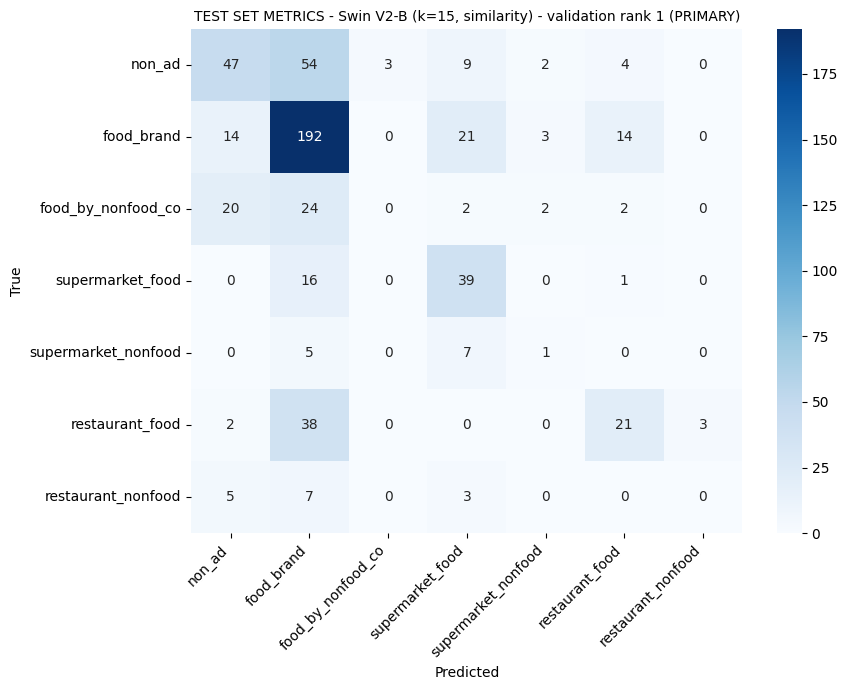


TEST SET METRICS - ConvNeXt Base (k=10, similarity) - validation rank 2 (SECONDARY)
  Validation macro-F1: 0.4260
  Test time: feature extraction 12.51 s, neighbor search + voting 0.01 s
  Images:            561
  Accuracy:          0.5365
  Balanced accuracy: 0.3477
  Macro precision:   0.3344
  Macro recall:      0.3477
  Macro F1:          0.3213
  Weighted F1:       0.4918

PER-CLASS REPORT
                     precision    recall  f1-score   support

             non_ad     0.5392    0.4622    0.4977       119
         food_brand     0.5803    0.7254    0.6448       244
 food_by_nonfood_co     0.0000    0.0000    0.0000        50
   supermarket_food     0.5106    0.8571    0.6400        56
supermarket_nonfood     0.3333    0.0769    0.1250        13
    restaurant_food     0.3774    0.3125    0.3419        64
 restaurant_nonfood     0.0000    0.0000    0.0000        15

           accuracy                         0.5365       561
          macro avg     0.3344    0.3477    0.3213

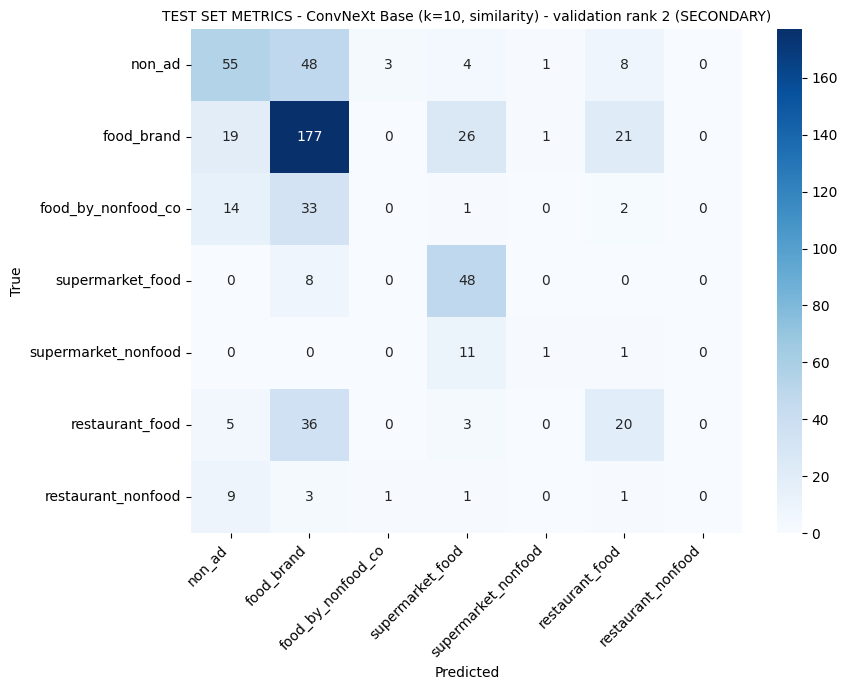


TEST SET METRICS - ResNeXt-101 (k=30, uniform) - validation rank 3 (SECONDARY)
  Validation macro-F1: 0.4176
  Test time: feature extraction 12.15 s, neighbor search + voting 0.01 s
  Images:            561
  Accuracy:          0.5009
  Balanced accuracy: 0.2875
  Macro precision:   0.3315
  Macro recall:      0.2875
  Macro F1:          0.2846
  Weighted F1:       0.4527

PER-CLASS REPORT
                     precision    recall  f1-score   support

             non_ad     0.6557    0.3361    0.4444       119
         food_brand     0.5093    0.7869    0.6184       244
 food_by_nonfood_co     0.0000    0.0000    0.0000        50
   supermarket_food     0.3500    0.5000    0.4118        56
supermarket_nonfood     0.2500    0.0769    0.1176        13
    restaurant_food     0.5556    0.3125    0.4000        64
 restaurant_nonfood     0.0000    0.0000    0.0000        15

           accuracy                         0.5009       561
          macro avg     0.3315    0.2875    0.2846     

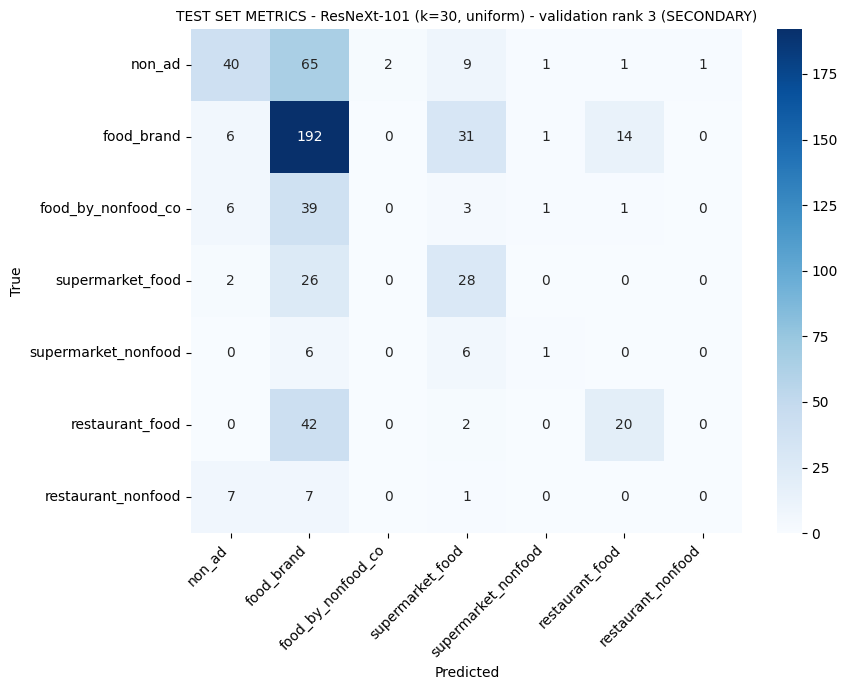


TEST SET METRICS - EfficientNet V2-M (k=15, similarity) - validation rank 4 (SECONDARY)
  Validation macro-F1: 0.4027
  Test time: feature extraction 24.32 s, neighbor search + voting 0.01 s
  Images:            561
  Accuracy:          0.4742
  Balanced accuracy: 0.2961
  Macro precision:   0.2775
  Macro recall:      0.2961
  Macro F1:          0.2761
  Weighted F1:       0.4339

PER-CLASS REPORT
                     precision    recall  f1-score   support

             non_ad     0.4434    0.3950    0.4178       119
         food_brand     0.5290    0.6721    0.5921       244
 food_by_nonfood_co     0.0000    0.0000    0.0000        50
   supermarket_food     0.4222    0.6786    0.5205        56
supermarket_nonfood     0.2000    0.0769    0.1111        13
    restaurant_food     0.3478    0.2500    0.2909        64
 restaurant_nonfood     0.0000    0.0000    0.0000        15

           accuracy                         0.4742       561
          macro avg     0.2775    0.2961    0.

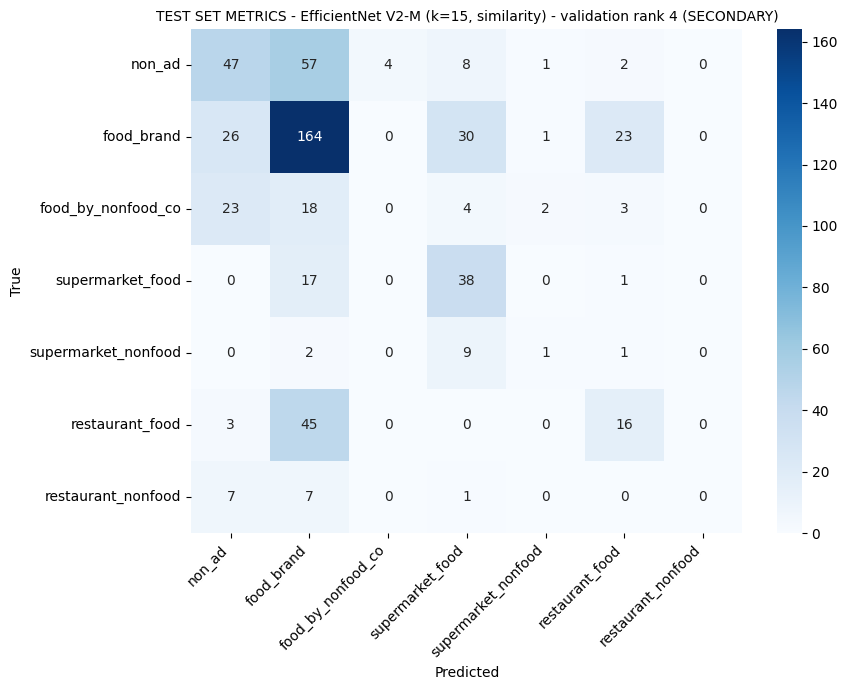


TEST SET METRICS - DINOv2 (k=1, uniform) - validation rank 5 (SECONDARY)
  Validation macro-F1: 0.3985
  Test time: feature extraction 15.02 s, neighbor search + voting 0.01 s
  Images:            561
  Accuracy:          0.5544
  Balanced accuracy: 0.3834
  Macro precision:   0.3654
  Macro recall:      0.3834
  Macro F1:          0.3570
  Weighted F1:       0.5276

PER-CLASS REPORT
                     precision    recall  f1-score   support

             non_ad     0.6066    0.6218    0.6141       119
         food_brand     0.6157    0.6434    0.6293       244
 food_by_nonfood_co     0.2222    0.0400    0.0678        50
   supermarket_food     0.4681    0.7857    0.5867        56
supermarket_nonfood     0.1667    0.0769    0.1053        13
    restaurant_food     0.4783    0.5156    0.4962        64
 restaurant_nonfood     0.0000    0.0000    0.0000        15

           accuracy                         0.5544       561
          macro avg     0.3654    0.3834    0.3570       561


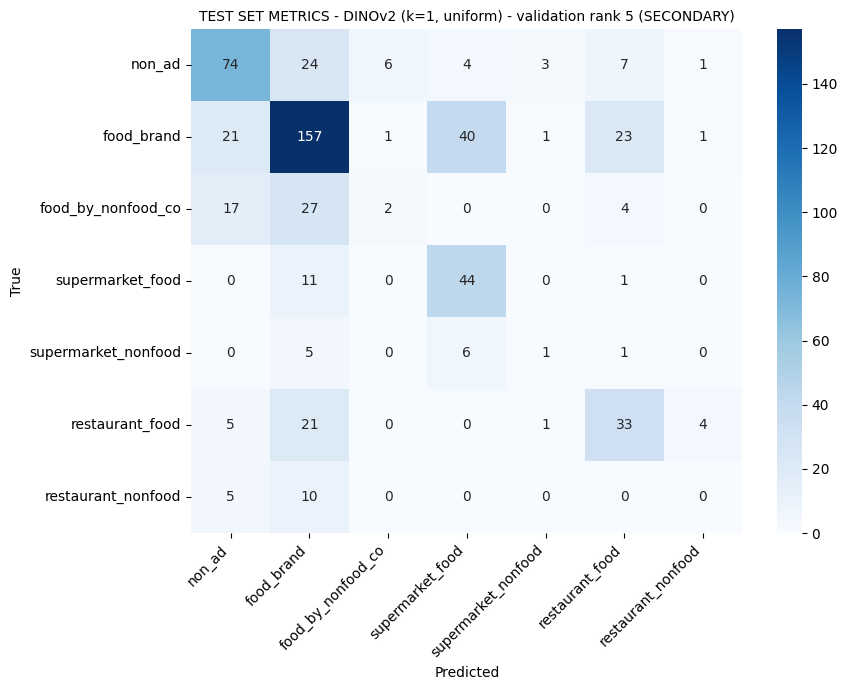


TEST SET METRICS - ViT-B/16 (k=5, similarity) - validation rank 6 (SECONDARY)
  Validation macro-F1: 0.3981
  Test time: feature extraction 11.76 s, neighbor search + voting 0.01 s
  Images:            561
  Accuracy:          0.5241
  Balanced accuracy: 0.3343
  Macro precision:   0.3054
  Macro recall:      0.3343
  Macro F1:          0.3159
  Weighted F1:       0.4927

PER-CLASS REPORT
                     precision    recall  f1-score   support

             non_ad     0.5701    0.5126    0.5398       119
         food_brand     0.5862    0.6967    0.6367       244
 food_by_nonfood_co     0.0000    0.0000    0.0000        50
   supermarket_food     0.4872    0.6786    0.5672        56
supermarket_nonfood     0.1250    0.0769    0.0952        13
    restaurant_food     0.3692    0.3750    0.3721        64
 restaurant_nonfood     0.0000    0.0000    0.0000        15

           accuracy                         0.5241       561
          macro avg     0.3054    0.3343    0.3159      

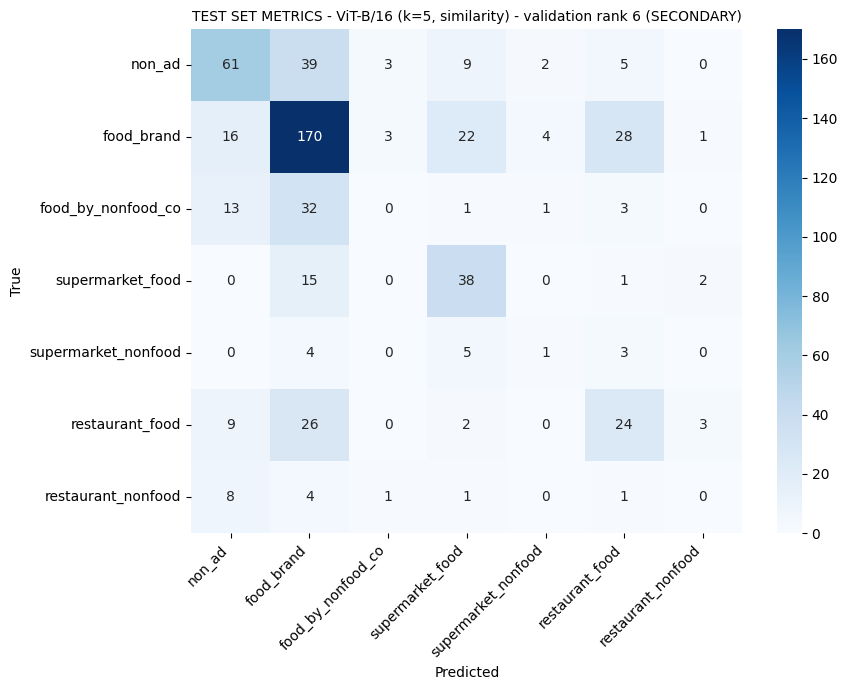

In [9]:
test_rows = []
test_outputs = {}  # extractor -> dict(scores, pred, metrics, per_class)
for name, config in selected.items():
    sims, idx = neighbors[name]["test"]
    started = time.perf_counter()
    scores = knn_scores(sims, idx, TRAIN_ONEHOT, config["k"], config["weighting"])
    pred = knn_predict(scores, idx, TRAIN_ONEHOT)
    vote_seconds = time.perf_counter() - started
    metrics = compute_metrics(Y["test"], pred)
    test_outputs[name] = {"scores": scores, "pred": pred, "metrics": metrics}
    test_rows.append({
        "extractor": name,
        "primary": name == PRIMARY_EXTRACTOR,
        **config,
        "val_macro_f1": float(best_per_extractor.set_index("extractor").loc[name, "macro_f1"]),
        **{f"test_{key}": value for key, value in metrics.items()},
        "train_feature_seconds": feature_seconds[name]["train"],
        "test_feature_seconds": feature_seconds[name]["test"],
        "test_search_seconds": search_seconds[name]["test"] + vote_seconds,
    })

test_summary = pd.DataFrame(test_rows)
print("TEST SET SUMMARY")
print(test_summary[["extractor", "primary", "k", "weighting", "val_macro_f1"] + [f"test_{k}" for k in METRIC_KEYS]]
      .round(4).to_string(index=False))

# Full report for every extractor, in validation order (rank 1 = primary).
for rank, name in enumerate(best_per_extractor["extractor"], 1):
    out, row, config = test_outputs[name], test_summary.set_index("extractor").loc[name], selected[name]
    out["per_class"] = report_configuration(
        f"TEST SET METRICS - {name} (k={config['k']}, {config['weighting']}) - validation rank {rank}"
        + (" (PRIMARY)" if name == PRIMARY_EXTRACTOR else " (SECONDARY)"),
        Y["test"], out["pred"], out["metrics"],
        extra_lines=[
            f"Validation macro-F1: {row['val_macro_f1']:.4f}",
            f"Test time: feature extraction {row['test_feature_seconds']:.2f} s, "
            f"neighbor search + voting {row['test_search_seconds']:.2f} s",
        ],
    )

primary = test_outputs[PRIMARY_EXTRACTOR]

## Export results

Writes the split manifest, validation grid, test summary, per-class test metrics (all extractors), primary test predictions and run metadata to `runs/knn/` (downloaded as a zip on Colab).

In [10]:
RESULTS_DIR = Path.cwd() / "runs" / "knn"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

save_split_manifest(RESULTS_DIR)
val_grid.to_csv(RESULTS_DIR / "val_grid.csv", index=False)
test_summary.to_csv(RESULTS_DIR / "test_summary.csv", index=False)
pd.concat([out["per_class"].assign(extractor=name) for name, out in test_outputs.items()]).to_csv(
    RESULTS_DIR / "test_per_class.csv", index=False)
test_df[["image_name", "tip", "class_name", "group"]].assign(
    predicted=[CLASS_NAMES[i] for i in primary["pred"]],
    **{f"vote_{name}": primary["scores"][:, i] for i, name in enumerate(CLASS_NAMES)},
).to_csv(RESULTS_DIR / "test_predictions_primary.csv", index=False)

with open(RESULTS_DIR / "run_metadata.json", "w") as f:
    json.dump({
        **environment_metadata(),
        "strategy": "knn",
        "primary_extractor": PRIMARY_EXTRACTOR,
        "selected_configs": selected,
        "selection_criterion": "validation macro-F1 (argmax of neighbor votes); ties keep configured order",
        "k_values": list(K_VALUES),
        "weightings": list(WEIGHTINGS),
        "similarity": "cosine on L2-normalized embeddings, exact search",
        "tie_break": "class of the nearest neighbor",
        "preprocessing": {config["name"]: repr(config["transform"]) for config in EXTRACTOR_CONFIGS if config["name"] in features},
        "feature_seconds": feature_seconds,
        "search_seconds": search_seconds,
        "timing_scope": "wall-clock seconds; excludes model loading and weight downloads",
    }, f, indent=2)

print(f"Results written to {RESULTS_DIR}")
for path in sorted(RESULTS_DIR.iterdir()):
    print(f"  - {path.name}")
download_results(RESULTS_DIR, "knn_multiclass_results")

Results written to /content/runs/knn
  - run_metadata.json
  - split_manifest.csv
  - test_per_class.csv
  - test_predictions_primary.csv
  - test_summary.csv
  - val_grid.csv
Archive: /content/knn_multiclass_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Real images test

Qualitative predictions of the primary configuration on one seeded random test image per class. Scores are neighbor vote fractions, not calibrated probabilities.

KNN primary configuration: Swin V2-B {'k': 15, 'weighting': 'similarity'}



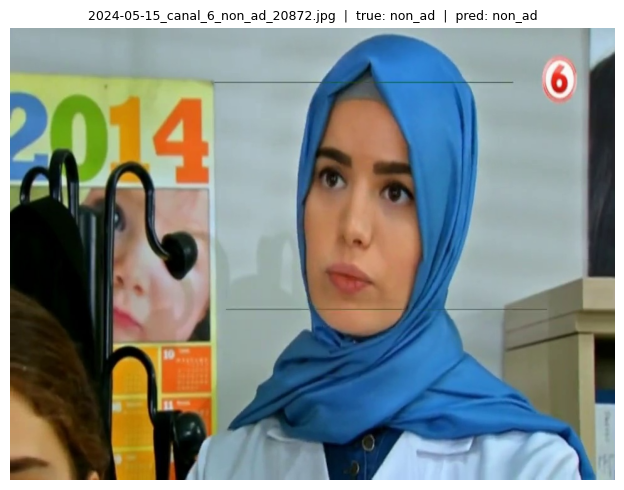

True: non_ad (tip 0)  Predicted: non_ad  Correct: True
  Top neighbor vote fractions:
  - non_ad              : 0.571
  - food_brand          : 0.258
  - supermarket_food    : 0.113



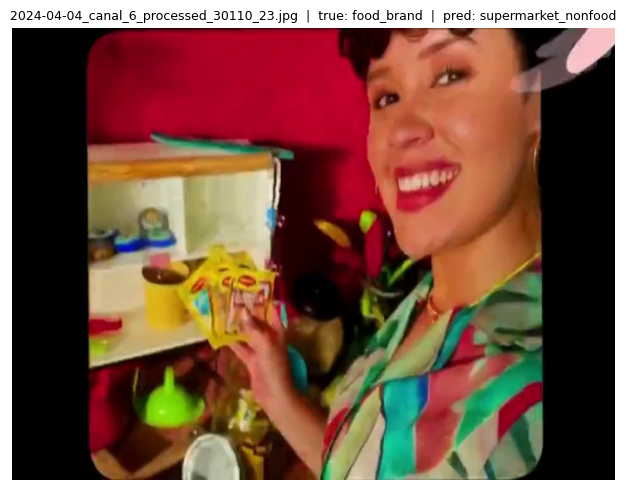

True: food_brand (tip 2)  Predicted: supermarket_nonfood  Correct: False
  Top neighbor vote fractions:
  - supermarket_nonfood : 0.478
  - food_brand          : 0.384
  - non_ad              : 0.138



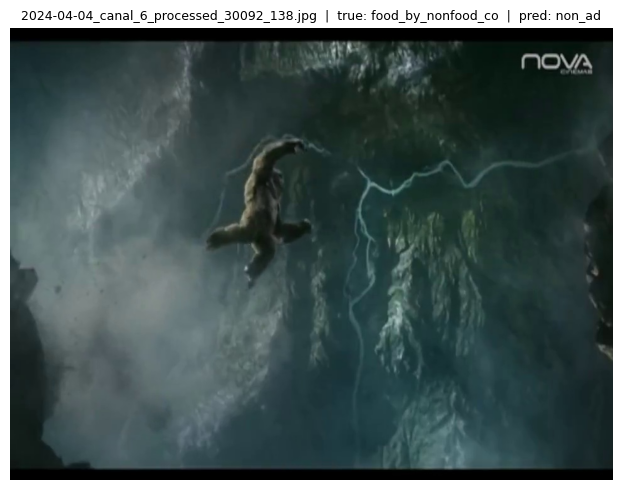

True: food_by_nonfood_co (tip 3)  Predicted: non_ad  Correct: False
  Top neighbor vote fractions:
  - non_ad              : 0.543
  - food_brand          : 0.457
  - food_by_nonfood_co  : 0.000



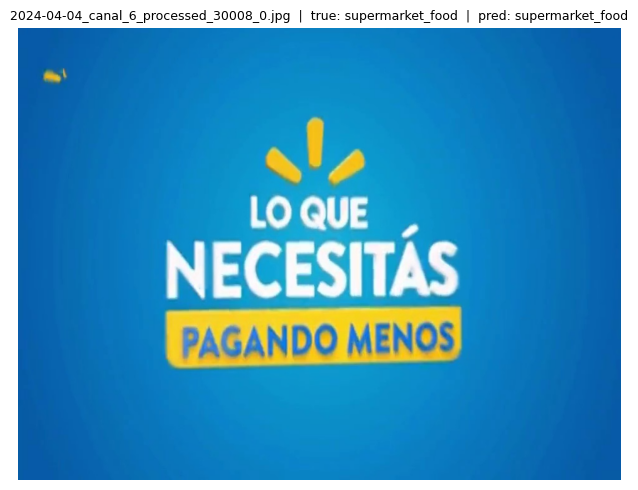

True: supermarket_food (tip 5)  Predicted: supermarket_food  Correct: True
  Top neighbor vote fractions:
  - supermarket_food    : 0.506
  - food_brand          : 0.314
  - restaurant_food     : 0.123



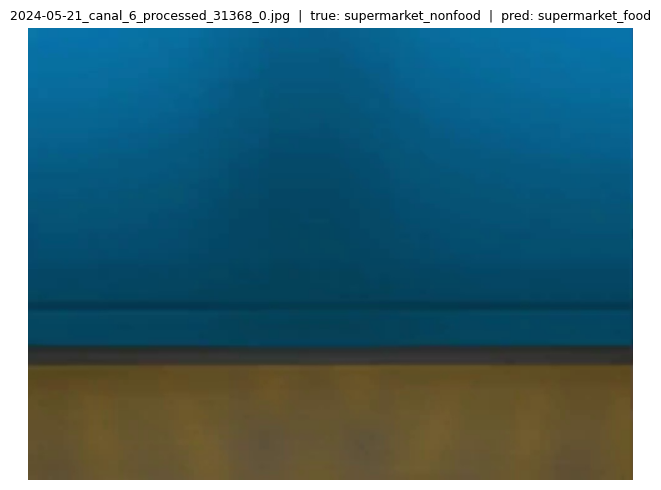

True: supermarket_nonfood (tip 6)  Predicted: supermarket_food  Correct: False
  Top neighbor vote fractions:
  - supermarket_food    : 0.402
  - food_brand          : 0.340
  - restaurant_food     : 0.195



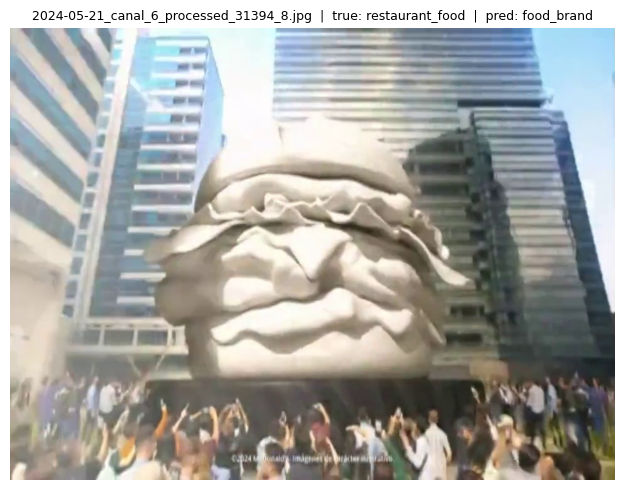

True: restaurant_food (tip 7)  Predicted: food_brand  Correct: False
  Top neighbor vote fractions:
  - food_brand          : 0.609
  - non_ad              : 0.391
  - food_by_nonfood_co  : 0.000



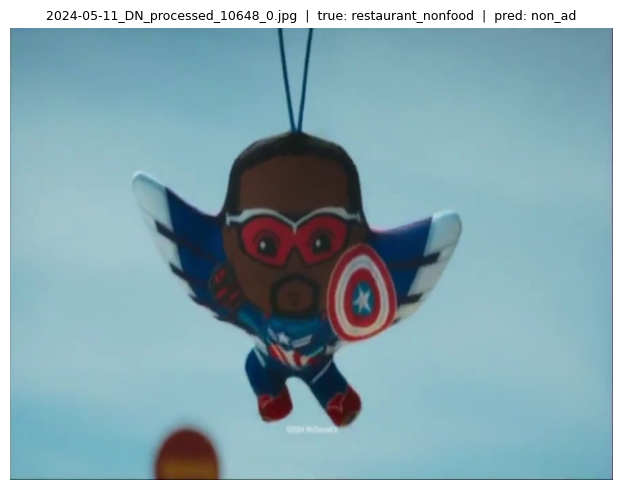

True: restaurant_nonfood (tip 8)  Predicted: non_ad  Correct: False
  Top neighbor vote fractions:
  - non_ad              : 0.472
  - food_brand          : 0.266
  - supermarket_food    : 0.262



In [11]:
print(f"KNN primary configuration: {PRIMARY_EXTRACTOR} {selected[PRIMARY_EXTRACTOR]}\n")
for idx in sample_test_indices(per_class=1):
    row = test_df.loc[idx]
    scores, pred = primary["scores"][idx], int(primary["pred"][idx])
    show_image(row["image_path"], f"{row['image_name']}  |  true: {row['class_name']}  |  pred: {CLASS_NAMES[pred]}")
    print(f"True: {row['class_name']} (tip {row['tip']})  Predicted: {CLASS_NAMES[pred]}  Correct: {pred == row['y']}")
    print("  Top neighbor vote fractions:")
    for i in np.argsort(-scores)[:3]:
        print(f"  - {CLASS_NAMES[i]:<20}: {scores[i]:.3f}")
    print()